# Calibration de caméra : notebook complet

1. Paramètres et points 3D du damier
2. Détection des coins (rapide)
3. Calibration `cv2.calibrateCamera`
4. Erreur de reprojection, retrait des images aberrantes, recalibration
5. Sauvegarde des résultats
6. Correction de la distorsion (avant / après)
7. **Focale en mètre** et `cv2.calibrationMatrixValues`
8. Estimation de pose : axes 3D et cube
9. Bonus : stabilité de K selon le nombre d'images

`COLS` et `ROWS` = nombre de **coins intérieurs**.

## Imports et paramètres

In [36]:
import glob, os, json, time

import cv2
import numpy as np
import matplotlib.pyplot as plt


IMAGES_DIR = "images"
COLS, ROWS = 8, 5          # coins intérieurs (horizontal, vertical)
SQUARE_MM = 20.0           # taille réelle d'un carré, en mm
MAX_DIM = 1600             # taille réduite pour la détection

FIX_K3 = True              # recommandé pour un téléphone
ZERO_TANGENT = True        # ignore p1, p2
OUTLIER_SIGMA = 1.5        # retire les images dont l'erreur > moyenne + 1.5 écart-type (None = ne rien retirer)

# Taille du capteur en mm
SENSOR_W_MM = 3.894
SENSOR_H_MM = 5.192
# -------------------------------------------

OUT_CORNERS = "output/corners"
OUT_POSE = "output/pose"
OUT_RESULTS = "results"
for d in (OUT_CORNERS, OUT_POSE, OUT_RESULTS):
    os.makedirs(d, exist_ok=True)

PATTERN = (COLS, ROWS)
# Orientation brute du capteur
READ_FLAGS = cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## 1. Points 3D du damier (`objp`)
Damier plan (Z = 0), coordonnées en **mm**.

In [37]:
objp = np.zeros((ROWS * COLS, 3), np.float32)
objp[:, :2] = np.mgrid[0:COLS, 0:ROWS].T.reshape(-1, 2)
objp *= SQUARE_MM

print(objp.shape)
print(objp[:4])

(40, 3)
[[ 0.  0.  0.]
 [20.  0.  0.]
 [40.  0.  0.]
 [60.  0.  0.]]


## 2. Détection des coins (version rapide)

In [38]:
def list_images(folder):
    files = []
    for e in ("jpg", "jpeg", "png", "bmp"):
        files += glob.glob(os.path.join(folder, f"*.{e}"))
        files += glob.glob(os.path.join(folder, f"*.{e.upper()}"))
    return sorted(set(files))


def find_corners(gray, pattern, max_dim):
    """Détection sur image réduite, affinement sub-pixel en pleine résolution."""
    h, w = gray.shape
    scale, small = 1.0, gray
    if max_dim and max(h, w) > max_dim:
        scale = max_dim / max(h, w)
        small = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

    flags = cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE
    found, corners = cv2.findChessboardCorners(small, pattern, flags)
    if not found:
        return False, None

    corners = (corners / scale).astype(np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
    corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)
    return True, corners


files = list_images(IMAGES_DIR)
print(f"{len(files)} images trouvées dans '{IMAGES_DIR}'")

objpoints, imgpoints, used, rejected, previews = [], [], [], [], []
image_size = None  # (largeur, hauteur)
t0 = time.time()

for path in files:
    name = os.path.basename(path)
    img = cv2.imread(path, READ_FLAGS)
    img = cv2.imread(path)
    h, w = img.shape[:2]
    if (w, h) != image_size:            # image_size = (4080, 3072)
        img = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)    
    if img is None:
        print(f"[ERREUR] lecture impossible : {name}")
        rejected.append(name)
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    size = (gray.shape[1], gray.shape[0])
    if image_size is None:
        image_size = size
    elif size != image_size:
        print(f"[IGNORÉE] {name} : taille {size} différente de {image_size}")
        rejected.append(name)
        continue

    found, corners = find_corners(gray, PATTERN, MAX_DIM)
    if not found:
        print(f"[NON DÉTECTÉ] {name}")
        rejected.append(name)
        continue

    objpoints.append(objp)
    imgpoints.append(corners)
    used.append(name)

    vis = img.copy()
    cv2.drawChessboardCorners(vis, PATTERN, corners, True)
    cv2.imwrite(os.path.join(OUT_CORNERS, f"corners_{name}"), vis)
    previews.append((name, cv2.resize(vis, None, fx=0.2, fy=0.2, interpolation=cv2.INTER_AREA)))
    print(f"[OK] {name}")

print(f"\nImages utilisées : {len(used)} / {len(files)}  | taille : {image_size}  | {time.time()-t0:.0f} s")
if 0 < len(used) < 10:
    print("ATTENTION : moins de 10 images valides, prenez plus de photos variées.")

93 images trouvées dans 'images'
[NON DÉTECTÉ] IMG20261104234334.jpg
[NON DÉTECTÉ] IMG20261104234342.jpg
[NON DÉTECTÉ] IMG20261104234349.jpg
[NON DÉTECTÉ] IMG20261104234353.jpg
[NON DÉTECTÉ] IMG20261104234407.jpg
[NON DÉTECTÉ] IMG20261104234409.jpg
[NON DÉTECTÉ] IMG20261104234518.jpg
[OK] IMG20261104234521.jpg
[OK] IMG20261104234523.jpg
[NON DÉTECTÉ] IMG20261104234526.jpg
[NON DÉTECTÉ] IMG20261104234532.jpg
[NON DÉTECTÉ] IMG20261104234533.jpg
[OK] IMG20261104234536.jpg
[NON DÉTECTÉ] IMG20261104234538.jpg
[OK] IMG20261104234540.jpg
[NON DÉTECTÉ] IMG20261104234543.jpg
[NON DÉTECTÉ] IMG20261104234546.jpg
[OK] IMG20261104234551.jpg
[NON DÉTECTÉ] IMG20261104234553.jpg
[NON DÉTECTÉ] IMG20261104234604.jpg
[NON DÉTECTÉ] IMG20261104234607.jpg
[NON DÉTECTÉ] IMG20261104234608.jpg
[OK] IMG20261104234620.jpg
[OK] IMG20261104234621.jpg
[NON DÉTECTÉ] IMG20261104234625.jpg
[OK] IMG20261104234626.jpg
[OK] IMG20261104234628.jpg
[NON DÉTECTÉ] IMG20261104234631.jpg
[NON DÉTECTÉ] IMG20261104234634.jpg
[NON

### Aperçu des détections

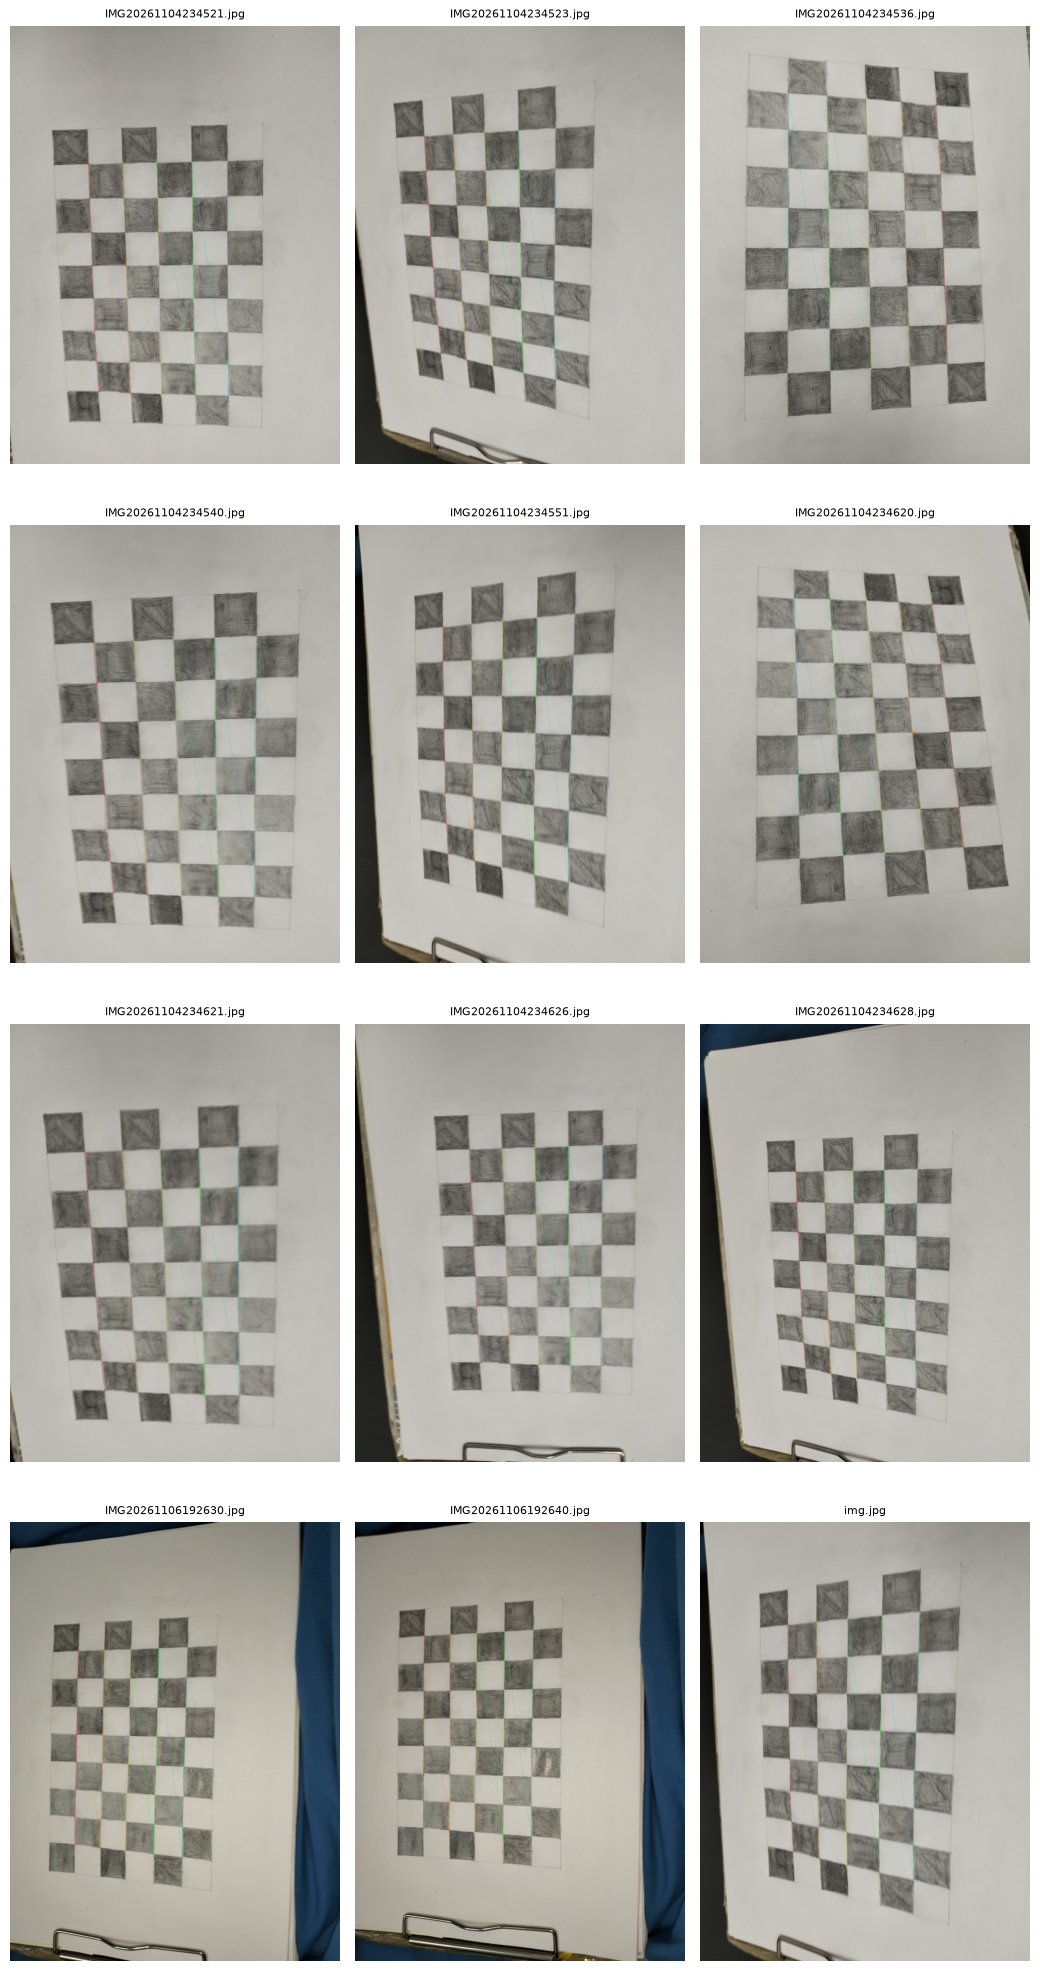

In [39]:
def show_grid(items, ncols=3, max_items=12):
    items = items[:max_items]
    if not items:
        print("Rien à afficher.")
        return
    h, w = items[0][1].shape[:2]
    nrows = int(np.ceil(len(items) / ncols))
    cell_w = 3.5
    cell_h = cell_w * h / w + 0.4          # hauteur adaptée au format portrait
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell_w * ncols, cell_h * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (name, im) in zip(axes, items):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(name, fontsize=8)
    plt.tight_layout()
    plt.show()

show_grid(previews)

In [40]:
def draw_corners_thick(img, pattern, corners, thickness=None):
    """Comme drawChessboardCorners, mais avec une épaisseur adaptée à la taille de l'image."""
    vis = img.copy()
    h, w = vis.shape[:2]
    th = thickness or max(3, round(max(h, w) / 400))   # environ 10 px pour 4080 px
    cols, rows = pattern
    pts = np.round(corners.reshape(-1, 2)).astype(int)
    palette = [(0, 0, 255), (0, 128, 255), (0, 220, 220), (0, 255, 0),
               (255, 255, 0), (255, 0, 0), (255, 0, 255)]   # BGR, couleurs d'OpenCV

    for r in range(rows):
        color = palette[r % len(palette)]
        row = pts[r * cols:(r + 1) * cols]
        for i, p in enumerate(row):
            if i > 0:
                cv2.line(vis, tuple(row[i - 1]), tuple(p), color, th, cv2.LINE_AA)
            cv2.circle(vis, tuple(p), 3 * th, color, th, cv2.LINE_AA)
        if r + 1 < rows:   # trait diagonal vers le début de la ligne suivante
            cv2.line(vis, tuple(row[-1]), tuple(pts[(r + 1) * cols]), color, th, cv2.LINE_AA)
    return vis

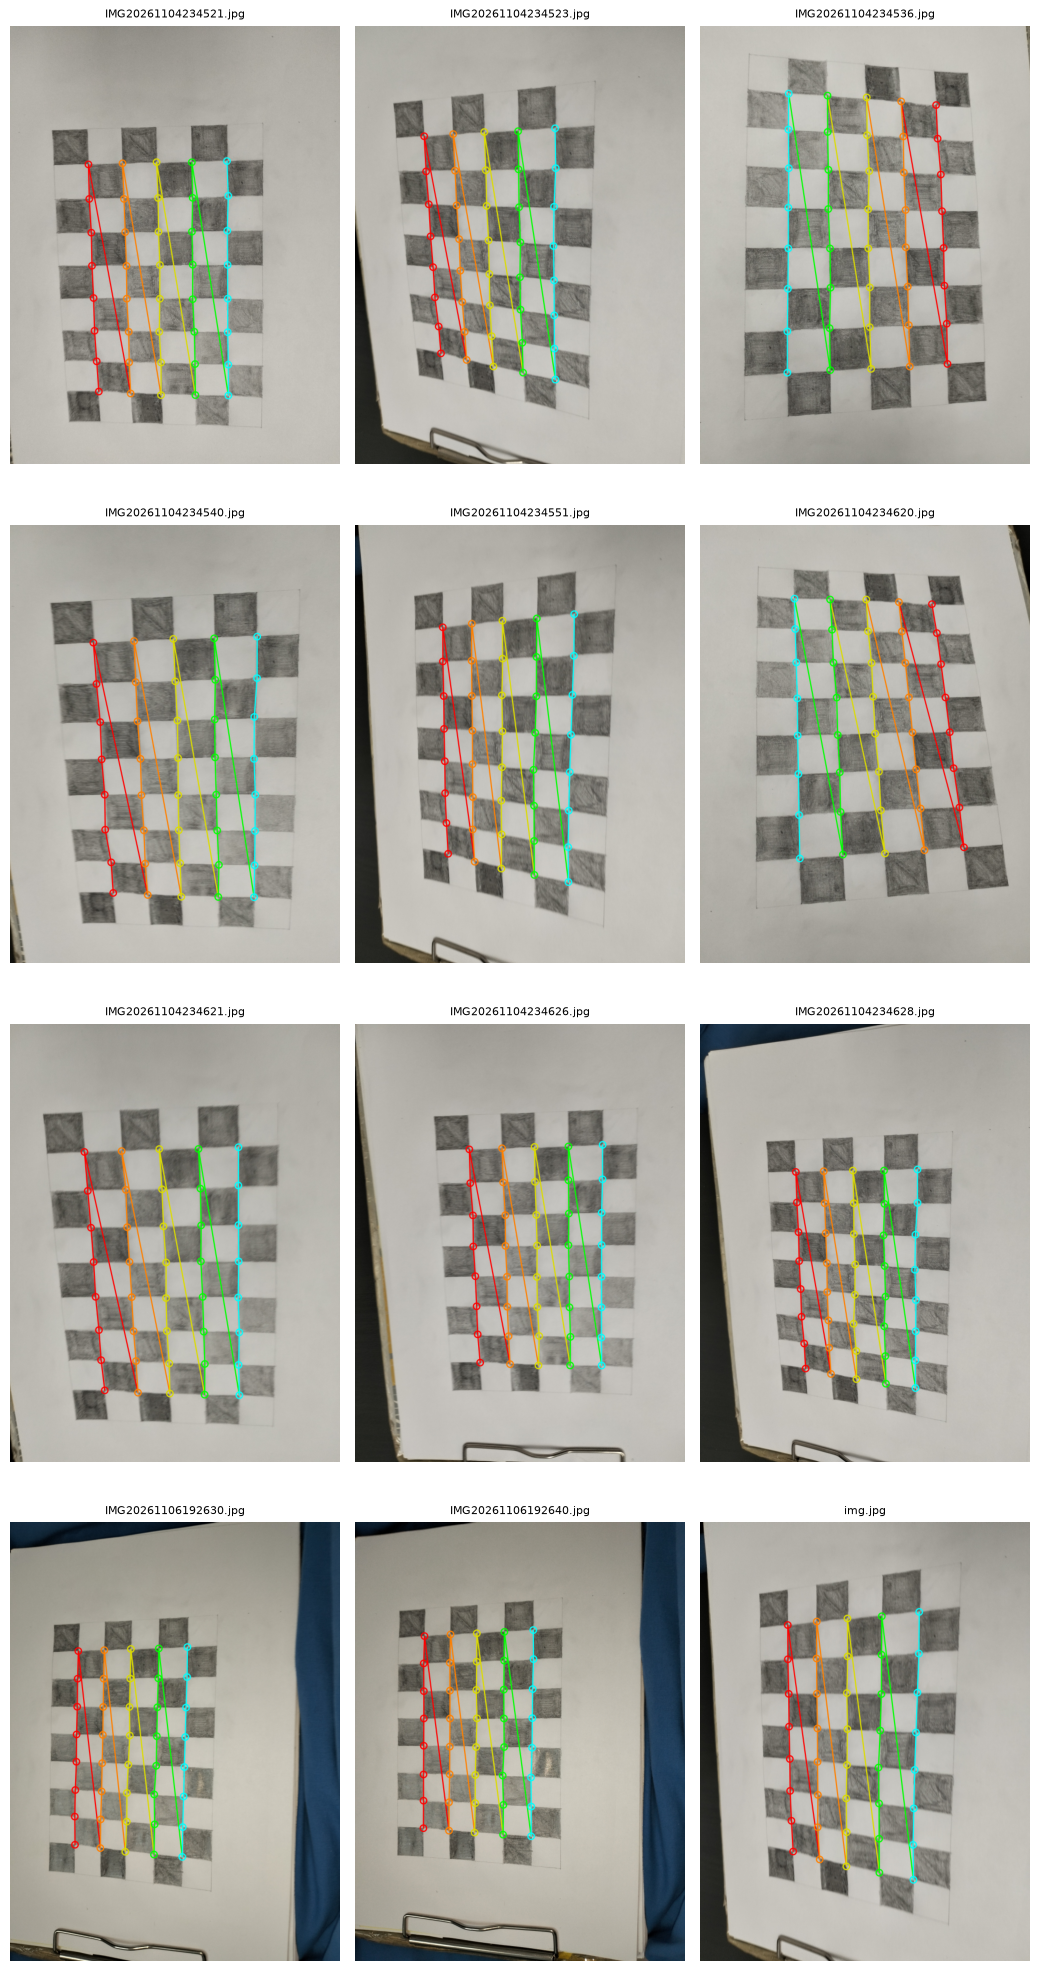

In [41]:
previews = []
for name, corners in zip(used, imgpoints):
    img = cv2.imread(os.path.join(IMAGES_DIR, name))
    if (img.shape[1], img.shape[0]) != image_size:
        img = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)
    vis = draw_corners_thick(img, PATTERN, corners)
    cv2.imwrite(os.path.join(OUT_CORNERS, f"corners_{name}"), vis)
    previews.append((name, cv2.resize(vis, None, fx=0.2, fy=0.2, interpolation=cv2.INTER_AREA)))

show_grid(previews)

## 3. Calibration (`cv2.calibrateCamera`)

In [42]:
assert len(used) >= 3, "Pas assez d'images valides pour calibrer."

FLAGS = 0
if FIX_K3:
    FLAGS |= cv2.CALIB_FIX_K3
if ZERO_TANGENT:
    FLAGS |= cv2.CALIB_ZERO_TANGENT_DIST


def calibrate(obj, img, size):
    return cv2.calibrateCamera(obj, img, size, None, None, flags=FLAGS)


def reproj_errors(obj, img, rvecs, tvecs, K, dist):
    errs = []
    for i in range(len(obj)):
        proj, _ = cv2.projectPoints(obj[i], rvecs[i], tvecs[i], K, dist)
        a = img[i].reshape(-1, 2)
        b = proj.reshape(-1, 2)
        errs.append(np.sqrt(np.mean(np.sum((a - b) ** 2, axis=1))))
    return np.array(errs)


def print_calib(rms, K, dist, errs):
    print(f"RMS (calibrateCamera) : {rms:.4f} px | erreur moyenne : {errs.mean():.4f} px")
    print(np.array2string(K, precision=3, suppress_small=True))
    print(f"fx = {K[0,0]:.2f} px  fy = {K[1,1]:.2f} px  cx = {K[0,2]:.2f}  cy = {K[1,2]:.2f}")
    print("Distorsion (k1, k2, p1, p2, k3) :", np.round(dist.ravel(), 5))


rms, K, dist, rvecs, tvecs = calibrate(objpoints, imgpoints, image_size)
errors = reproj_errors(objpoints, imgpoints, rvecs, tvecs, K, dist)

print(f"Taille image : {image_size[0]} x {image_size[1]} px\n")
print_calib(rms, K, dist, errors)

Taille image : 3072 x 4080 px

RMS (calibrateCamera) : 6.8113 px | erreur moyenne : 6.7003 px
[[3394.837    0.    1548.467]
 [   0.    3370.764 2045.986]
 [   0.       0.       1.   ]]
fx = 3394.84 px  fy = 3370.76 px  cx = 1548.47  cy = 2045.99
Distorsion (k1, k2, p1, p2, k3) : [ 0.17024 -0.87272  0.       0.       0.     ]


## 4. Erreur de reprojection, images aberrantes, recalibration
Moins de 0,5 px est généralement bon. Les images dont l'erreur dépasse `moyenne + OUTLIER_SIGMA × écart-type` sont retirées, puis on recalibre et on compare.

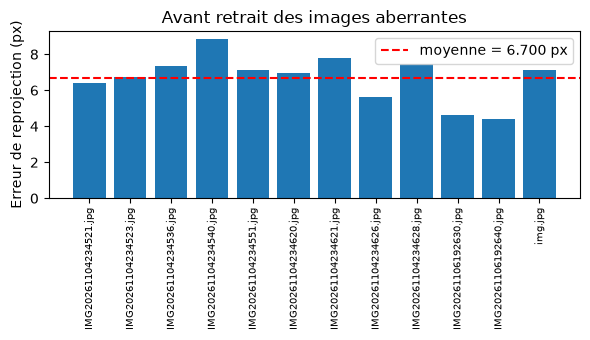

Seuil = 8.538 px | images retirées : ['IMG20261104234540.jpg']


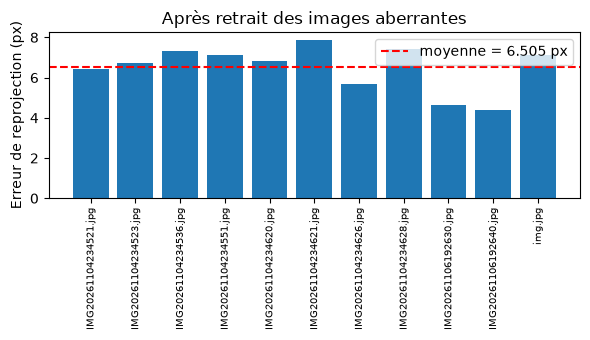


--- Avant / après ---
images : 12 -> 11
erreur moyenne : 6.7003 -> 6.5046 px
fx : 3394.84 -> 3413.59 | fy : 3370.76 -> 3389.23
cx : 1548.47 -> 1536.72 | cy : 2045.99 -> 2047.15

Calibration finale :
RMS (calibrateCamera) : 6.5936 px | erreur moyenne : 6.5046 px
[[3413.585    0.    1536.721]
 [   0.    3389.229 2047.152]
 [   0.       0.       1.   ]]
fx = 3413.59 px  fy = 3389.23 px  cx = 1536.72  cy = 2047.15
Distorsion (k1, k2, p1, p2, k3) : [ 0.16956 -0.89304  0.       0.       0.     ]


In [43]:
def plot_errors(errs, names, title, path=None):
    plt.figure(figsize=(max(6, 0.4 * len(names)), 3.5))
    plt.bar(range(len(errs)), errs)
    plt.axhline(errs.mean(), color="r", ls="--", label=f"moyenne = {errs.mean():.3f} px")
    plt.xticks(range(len(errs)), names, rotation=90, fontsize=7)
    plt.ylabel("Erreur de reprojection (px)")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=150)
    plt.show()


plot_errors(errors, used, "Avant retrait des images aberrantes",
            os.path.join(OUT_RESULTS, "reprojection_error_before.png"))

before = dict(n=len(used), rms=rms, mean_err=errors.mean(), K=K.copy(), dist=dist.copy())

if OUTLIER_SIGMA is not None and len(used) >= 10:
    thr = errors.mean() + OUTLIER_SIGMA * errors.std()
    keep = [i for i in range(len(used)) if errors[i] <= thr]
    removed = [used[i] for i in range(len(used)) if i not in keep]
    print(f"Seuil = {thr:.3f} px | images retirées : {removed if removed else 'aucune'}")
    if removed and len(keep) >= 8:
        objpoints = [objpoints[i] for i in keep]
        imgpoints = [imgpoints[i] for i in keep]
        used = [used[i] for i in keep]
        rms, K, dist, rvecs, tvecs = calibrate(objpoints, imgpoints, image_size)
        errors = reproj_errors(objpoints, imgpoints, rvecs, tvecs, K, dist)
        plot_errors(errors, used, "Après retrait des images aberrantes",
                    os.path.join(OUT_RESULTS, "reprojection_error_after.png"))
        print("\n--- Avant / après ---")
        print(f"images : {before['n']} -> {len(used)}")
        print(f"erreur moyenne : {before['mean_err']:.4f} -> {errors.mean():.4f} px")
        print(f"fx : {before['K'][0,0]:.2f} -> {K[0,0]:.2f} | fy : {before['K'][1,1]:.2f} -> {K[1,1]:.2f}")
        print(f"cx : {before['K'][0,2]:.2f} -> {K[0,2]:.2f} | cy : {before['K'][1,2]:.2f} -> {K[1,2]:.2f}")
        print("\nCalibration finale :")
        print_calib(rms, K, dist, errors)
else:
    print("Pas de retrait d'images (désactivé ou moins de 10 images).")

## 5. Sauvegarde dans `results/`

In [44]:
np.savez(
    os.path.join(OUT_RESULTS, "calib.npz"),
    K=K, dist=dist,
    rvecs=np.array(rvecs), tvecs=np.array(tvecs),
    rms=rms, errors=errors,
    image_size=np.array(image_size),
    pattern_size=np.array(PATTERN),
    square_size=SQUARE_MM,
    used_images=np.array(used),
    objpoints=np.array(objpoints),
    imgpoints=np.array(imgpoints),
)
print("Sauvegardé :", os.path.join(OUT_RESULTS, "calib.npz"))
if rejected:
    print("Images rejetées à la détection :", rejected)

Sauvegardé : results/calib.npz
Images rejetées à la détection : ['IMG20261104234334.jpg', 'IMG20261104234342.jpg', 'IMG20261104234349.jpg', 'IMG20261104234353.jpg', 'IMG20261104234407.jpg', 'IMG20261104234409.jpg', 'IMG20261104234518.jpg', 'IMG20261104234526.jpg', 'IMG20261104234532.jpg', 'IMG20261104234533.jpg', 'IMG20261104234538.jpg', 'IMG20261104234543.jpg', 'IMG20261104234546.jpg', 'IMG20261104234553.jpg', 'IMG20261104234604.jpg', 'IMG20261104234607.jpg', 'IMG20261104234608.jpg', 'IMG20261104234625.jpg', 'IMG20261104234631.jpg', 'IMG20261104234634.jpg', 'IMG20261104234636.jpg', 'IMG20261104234641.jpg', 'IMG20261104234642.jpg', 'IMG20261104234644_01.jpg', 'IMG20261106190930.jpg', 'IMG20261106190937.jpg', 'IMG20261106190942.jpg', 'IMG20261106190949.jpg', 'IMG20261106190951.jpg', 'IMG20261106190953.jpg', 'IMG20261106190956.jpg', 'IMG20261106190959.jpg', 'IMG20261106191001.jpg', 'IMG20261106191003.jpg', 'IMG20261106191005.jpg', 'IMG20261106191006.jpg', 'IMG20261106191008_01.jpg', 'IMG

## 6. Correction de la distorsion (avant / après)
`alpha = 0` : recadrage sans bandes noires. `alpha = 1` : tous les pixels conservés.

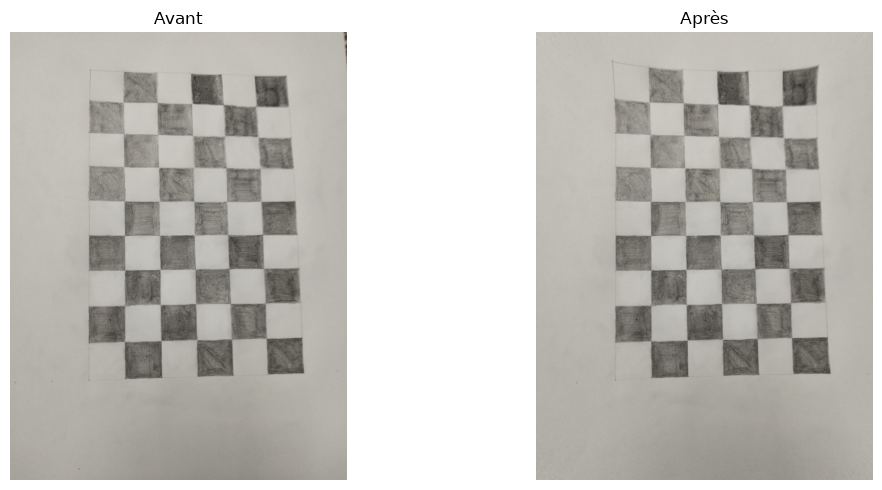

In [45]:
IDX = 0   # index de l'image dans `used`
img = cv2.imread(os.path.join(IMAGES_DIR, used[IDX]), READ_FLAGS)
h, w = img.shape[:2]
newK, roi = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), 0, (w, h))
und = cv2.undistort(img, K, dist, None, newK)

def small(im, s=0.2):
    return cv2.cvtColor(cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(small(img)); ax[0].set_title("Avant"); ax[0].axis("off")
ax[1].imshow(small(und)); ax[1].set_title("Après"); ax[1].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_RESULTS, "undistort_before_after.png"), dpi=150)
plt.show()

## 7. Focale en mètre et `cv2.calibrationMatrixValues`

La calibration donne `fx`, `fy` en **pixels**. Pour obtenir la focale en **mètres**, il faut la **taille physique du capteur** :

`f (mm) = fx × (largeur capteur / largeur image en pixels)`

La taille du capteur n'est pas connue par la calibration. Deux options : la renseigner à la main (`SENSOR_W_MM`, `SENSOR_H_MM`, fiche technique du téléphone), ou l'estimer avec l'EXIF : focale réelle `f` et focale équivalente 35 mm donnent le crop factor, donc la diagonale du capteur (43,27 mm / crop factor)

In [46]:
from PIL import Image

def read_exif(path):
    """Retourne (focale_mm, focale_equiv_35mm, modèle) depuis l'EXIF (None si absent)."""
    try:
        ex = Image.open(path).getexif()
        ifd = ex.get_ifd(0x8769)
        f = ifd.get(37386)        # FocalLength
        f35 = ifd.get(41989)      # FocalLengthIn35mmFilm
        model = ex.get(272)       # Model
        return (float(f) if f else None, float(f35) if f35 else None, model)
    except Exception as e:
        print("EXIF illisible :", e)
        return None, None, None

f_exif, f35_exif, model = read_exif(os.path.join(IMAGES_DIR, used[0]))
print(f"Modèle (EXIF) : {model}")
print(f"Focale EXIF : {f_exif} mm | équivalent 35 mm : {f35_exif} mm")

W, H = image_size
if SENSOR_W_MM and SENSOR_H_MM:
    sw, sh = SENSOR_W_MM, SENSOR_H_MM
    src = "valeurs renseignées à la main"
elif f_exif and f35_exif:
    crop = f35_exif / f_exif
    diag = 43.267 / crop                      # diagonale du capteur (mm)
    sw, sh = diag * W / np.hypot(W, H), diag * H / np.hypot(W, H)
    src = f"estimé via l'EXIF (crop factor = {crop:.2f})"
else:
    raise SystemExit("Renseignez SENSOR_W_MM et SENSOR_H_MM (fiche technique du téléphone).")

print(f"\nCapteur : {sw:.3f} x {sh:.3f} mm  [{src}]")

fovx, fovy, f_mm, pp_mm, aspect = cv2.calibrationMatrixValues(K, image_size, sw, sh)
pix_um = sw / W * 1000

print("\n===== calibrationMatrixValues =====")
print(f"Champ de vision : fovx = {fovx:.2f}°  fovy = {fovy:.2f}°")
print(f"Focale : {f_mm:.3f} mm = {f_mm/1000:.6f} m")
print(f"Point principal : ({pp_mm[0]:.3f}, {pp_mm[1]:.3f}) mm")
print(f"Rapport d'aspect fy/fx : {aspect:.4f}")
print(f"Taille d'un pixel : {pix_um:.3f} µm")

# Vérification à la main : f = fx x taille d'un pixel
f_manual_m = K[0, 0] * (sw / W) / 1000
print(f"\nVérification : fx x taille pixel = {f_manual_m:.6f} m")
if f_exif:
    print(f"Focale EXIF : {f_exif/1000:.6f} m | écart avec la calibration : {100*(f_mm-f_exif)/f_exif:+.1f} %")

Modèle (EXIF) : OPPO A78
Focale EXIF : 4.05 mm | équivalent 35 mm : 4.0 mm

Capteur : 3.894 x 5.192 mm  [valeurs renseignées à la main]

===== calibrationMatrixValues =====
Champ de vision : fovx = 48.45°  fovy = 62.09°
Focale : 4.327 mm = 0.004327 m
Point principal : (1.948, 2.605) mm
Rapport d'aspect fy/fx : 0.9929
Taille d'un pixel : 1.268 µm

Vérification : fx x taille pixel = 0.004327 m
Focale EXIF : 0.004050 m | écart avec la calibration : +6.8 %


## 8. Estimation de pose : axes 3D et cube
`cv2.solvePnP` donne la pose (rvec, tvec) du damier dans chaque image. On projette ensuite les axes (X rouge, Y vert, Z bleu) et un cube de côté 2 carrés. En repère OpenCV, Z positif entre dans le damier, donc le cube est dessiné avec Z négatif

IMG20261104234521.jpg : distance caméra-damier ≈ 251 mm
IMG20261104234551.jpg : distance caméra-damier ≈ 247 mm
IMG20261104234626.jpg : distance caméra-damier ≈ 262 mm
img.jpg : distance caméra-damier ≈ 247 mm


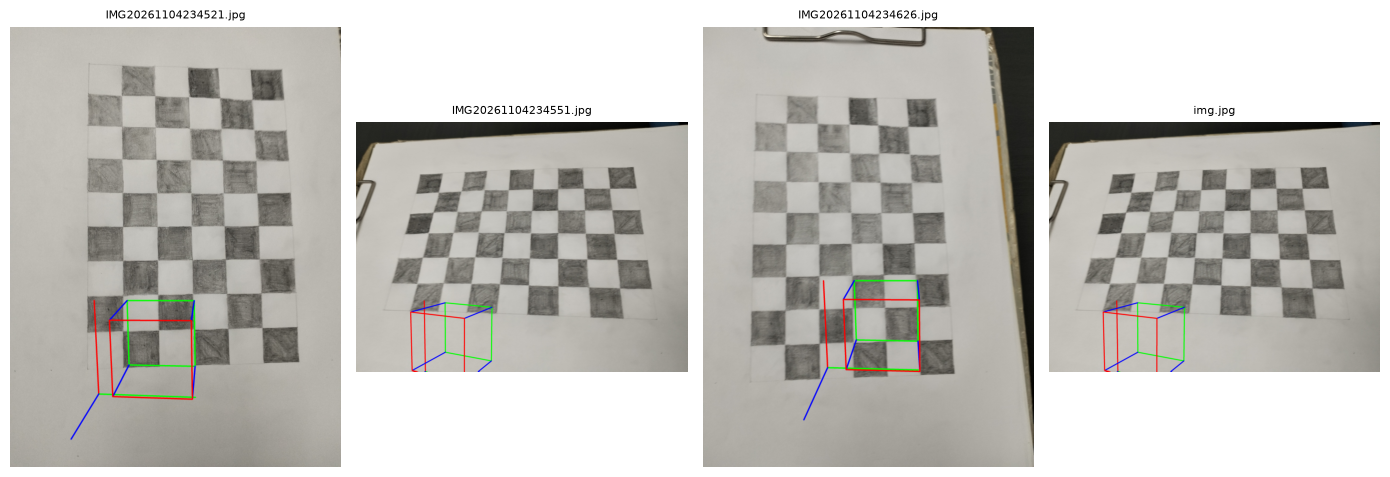

In [47]:
def draw_axes(img, K, dist, rvec, tvec, length, th):
    pts = np.float32([[0, 0, 0], [length, 0, 0], [0, length, 0], [0, 0, -length]])
    p, _ = cv2.projectPoints(pts, rvec, tvec, K, dist)
    p = p.reshape(-1, 2).astype(int)
    o = tuple(p[0])
    cv2.line(img, o, tuple(p[1]), (0, 0, 255), th)   # X rouge (BGR)
    cv2.line(img, o, tuple(p[2]), (0, 255, 0), th)   # Y vert
    cv2.line(img, o, tuple(p[3]), (255, 0, 0), th)   # Z bleu
    return img


def draw_cube(img, K, dist, rvec, tvec, side, th, origin=(0, 0)):
    ox, oy = origin
    base = [[ox, oy, 0], [ox + side, oy, 0], [ox + side, oy + side, 0], [ox, oy + side, 0]]
    top = [[x, y, -side] for x, y, _ in base]
    pts = np.float32(base + top)
    p, _ = cv2.projectPoints(pts, rvec, tvec, K, dist)
    p = np.int32(p.reshape(-1, 2))
    cv2.drawContours(img, [p[:4]], -1, (0, 255, 0), th)        # base verte
    for i in range(4):
        cv2.line(img, tuple(p[i]), tuple(p[i + 4]), (255, 0, 0), th)  # piliers bleus
    cv2.drawContours(img, [p[4:]], -1, (0, 0, 255), th)        # haut rouge
    return img


n_pose = min(4, len(used))
idxs = np.linspace(0, len(used) - 1, n_pose).astype(int)
pose_previews = []

for i in idxs:
    ok, rvec, tvec = cv2.solvePnP(objpoints[i], imgpoints[i], K, dist)
    if not ok:
        print("solvePnP a échoué pour", used[i])
        continue
    im = cv2.imread(os.path.join(IMAGES_DIR, used[i]), READ_FLAGS)
    th = max(3, int(round(max(im.shape[:2]) / 350)))
    draw_axes(im, K, dist, rvec, tvec, length=3 * SQUARE_MM, th=th)
    draw_cube(im, K, dist, rvec, tvec, side=2 * SQUARE_MM, th=th, origin=(SQUARE_MM, SQUARE_MM))
    cv2.imwrite(os.path.join(OUT_POSE, f"pose_{used[i]}"), im)
    pose_previews.append((used[i], cv2.resize(im, None, fx=0.2, fy=0.2, interpolation=cv2.INTER_AREA)))
    dist_cam = float(np.linalg.norm(tvec))
    print(f"{used[i]} : distance caméra-damier ≈ {dist_cam:.0f} mm")

show_grid(pose_previews, ncols=min(4, max(1, len(pose_previews))), max_items=4)

## 9. Bonus : stabilité de K selon le nombre d'images
On calibre avec 5, 8, 12... images tirées au hasard. Plus il y a d'images variées, plus `fx`, `fy`, `cx`, `cy` se stabilisent.

In [48]:
rng = np.random.default_rng(0)
rows_out = []
for n in sorted(set([5, 8, 12, len(used)])):
    if n > len(used) or n < 4:
        continue
    vals = []
    for _ in range(5 if n < len(used) else 1):
        sel = rng.choice(len(used), n, replace=False)
        _, Kn, dn, rv, tv = calibrate([objpoints[i] for i in sel], [imgpoints[i] for i in sel], image_size)
        vals.append([Kn[0, 0], Kn[1, 1], Kn[0, 2], Kn[1, 2]])
    vals = np.array(vals)
    rows_out.append((n, vals.mean(0), vals.std(0)))

print(f"{'N':>3} | {'fx':>16} | {'fy':>16} | {'cx':>16} | {'cy':>16}")
for n, m, s in rows_out:
    print(f"{n:>3} | " + " | ".join(f"{m[j]:8.1f} ± {s[j]:5.1f}" for j in range(4)))

  N |               fx |               fy |               cx |               cy
  5 |   3264.2 ± 240.7 |   3239.6 ± 236.0 |   1570.9 ±  70.0 |   2021.2 ±  43.4
  8 |   3408.6 ±  48.1 |   3384.8 ±  47.4 |   1541.3 ±  22.1 |   2046.8 ±   7.3
 11 |   3413.6 ±   0.0 |   3389.2 ±   0.0 |   1536.7 ±   0.0 |   2047.2 ±   0.0
